# Google Colab Environment Setup

**Python 3.12 required.** Before running, select **Runtime > Change runtime type > Runtime Version > 2026.07**, then reconnect. Google currently lists this Python 3.12 runtime; if it is no longer offered, use **Run with Binder** on the MDAS website. The default Python 3.13 runtime is incompatible with the published KaleCancer/PyKale requirements.

Run the setup cell below, then run the scientific cells individually in order. Setup downloads the companion module and installs a pinned CPU stack in **this notebook's active Python environment**; no separate notebook, Drive mount or upload is needed. The first installation may take several minutes. If libraries with different versions are already loaded, setup will ask you to **Restart session** and rerun setup before continuing. Reruns reuse the installed packages and downloaded files.

If you ran an earlier setup in this session, restart the session after the corrected packages are installed, then rerun setup. This includes Hugging Face Hub/Transformers imports: changing packages on disk does not replace already imported modules. Continue only when **MDAS ready** prints the corrected Hub version.

Every cell below this setup section is preserved from the original MDAS notebook, including its full training and advanced analyses. Use synthetic data only. Colab sessions are temporary; download work you want to keep.


In [ ]:
# Bootstrap only: scientific code below is unchanged.
import hashlib
from pathlib import Path
import runpy
import sys
from urllib.request import Request, urlopen

if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Python 3.12 is required. Choose Runtime > Change runtime type > Runtime Version > 2026.07, reconnect, then rerun setup. If unavailable, use Run with Binder.")

# Prefer a local checkout when testing; a fresh Colab session uses /content.
_candidates = [Path.cwd(), *(p / "notebooks/MDAS/cancer" for p in [Path.cwd(), *Path.cwd().parents])]
_mdas_dir = next((p for p in _candidates if (p / "colab_setup.py").is_file()), Path("/content/mdas-cancer/notebooks/MDAS/cancer"))
_mdas_dir.mkdir(parents=True, exist_ok=True)
_checksums = {'colab_setup.py': '0a9845ac9c0853140388a0908001ed63891ac7acae3a3002c23dab9f70344d00', 'colab-requirements.txt': 'f5c6948c023fe817ea38c3d535d988e3f8e0ddaa045aa37db0d2ee1bc63d946b', 'synthetic_data_generation.py': '4c599967243fb0f8f782bbcac4ae2bf3978884598ffbd54c048c87c147d89a22', 'synthetic_showcase_data.py': '52fdb92cad3dfa3781bc745234e0fcce19817d9b293d9fcfb91744162ebc5251'}
try:
    for _name, _digest in _checksums.items():
        _path = _mdas_dir / _name
        if not _path.is_file() or hashlib.sha256(_path.read_bytes().replace(b"\r\n", b"\n")).hexdigest() != _digest:
            print("MDAS: downloading", _name, flush=True)
            _url = "https://raw.githubusercontent.com/pykale/mdas/main/notebooks/MDAS/cancer/" + _name
            with urlopen(Request(_url, headers={"User-Agent": "MDAS-Colab"}), timeout=60) as _response:
                _contents = _response.read().replace(b"\r\n", b"\n")
            if hashlib.sha256(_contents).hexdigest() != _digest:
                raise RuntimeError("Setup revision mismatch. Reopen the latest Colab notebook from the MDAS website; no downloaded code was executed.")
            _temporary = _path.with_suffix(_path.suffix + ".tmp")
            _temporary.write_bytes(_contents)
            _temporary.replace(_path)
    runpy.run_path(str(_mdas_dir / "colab_setup.py"))["prepare"](_mdas_dir, showcase=True)
except OSError as _error:
    raise RuntimeError("MDAS download/install failed. Check internet access and rerun setup. The reviewed Colab support files must exist on public main.") from _error


# KaleCancer Example: Clinical covariates and WSI to predict cancer staging

You have a clinical table and a folder of pathology slide features.

In this tutorial, we will answer three questions:

1. Can these data predict cancer stage?
2. Does combining them beat using either one alone?
3. What is the model actually looking at?

The cohort is synthetic. We created the signal ourselves, so we can check that KaleCancer finds it. The results are purely illustrative.

In [1]:
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

from synthetic_showcase_data import make_showcase_cohort, PATCH_SIZE

RANDOM_STATE = 0

warnings.filterwarnings('ignore', message='IProgress not found')
EARLY, LATE, MODEL = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

## 1 Load Your Data

In [3]:
data_folder = '../../../data/synthetic_showcase'
make_showcase_cohort(data_folder)

table = pd.read_csv(data_folder + '/clinical.csv', index_col=0)
display(table.head())

,age,gender,stage
patient_id,,,
patient_000,63.047171,M,late
patient_001,49.600159,F,early
patient_002,67.504512,F,late
patient_003,69.405647,F,late
patient_004,40.489648,F,early


Wrap each source in a modality, and KaleCancer joins them by patient id. `required_modalities=[]` keeps all patients.

In [4]:
from kalecancer.loaddata import Tabular, PatchFeatures, Classification, MultimodalDataset

clinical = Tabular(table.drop(columns=['stage']))
slides = PatchFeatures.from_glob(data_folder + '/patches/*.h5', id_pattern=r'(patient_\d{3})\.h5')
target = Classification(labels=table['stage'], classes=['early', 'late'])

dataset = MultimodalDataset(
    modalities={'clinical': clinical, 'slides': slides},
    target=target,
    required_modalities=[]
)
display(dataset.summary())

,count
available: clinical,200
available: slides,180
available: target,200
included,200
included with clinical,200
included with slides,180
label: early,85
label: late,115


## Visualising the data

Patches each containing a coordinate pointing to the location of the WSI they encode.

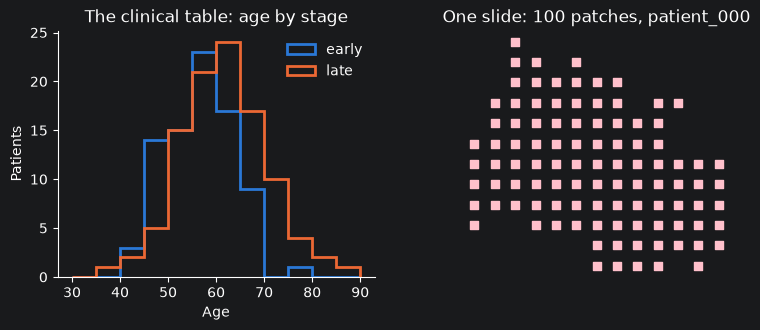

In [12]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.2))

for stage, colour in [('early', EARLY), ('late', LATE)]:
    left.hist(table.loc[table['stage'] == stage, 'age'], bins=range(30, 95, 5), histtype='step', linewidth=2, color=colour, label=stage)
left.set(title='The clinical table: age by stage', xlabel='Age', ylabel='Patients')
left.legend(frameon=False)

patient = slides.ids[0]
patches = slides.instances(patient)
right.scatter(patches['x'], patches['y'], marker='s', s=26, color='pink')
right.set_title(f'One slide: {len(patches)} patches, {patient}')
right.set_aspect('equal')
right.invert_yaxis()
right.axis('off')
plt.show()

## 2 Build a Model

For Intermediate Fusion: each modality gets an encoder, a fusion method combines them, and a head makes the prediction. Any `torch.nn.Module` can be an encoder.

`ABMIL` pools a slide's patches with attention. `MaskedMean` averages whichever modalities a patient has, so a patient with no slide still gets a prediction.

In [7]:
from kalecancer.model import ABMIL, MLP, IntermediateFusion, MaskedMean, ClassificationHead

# Needed to ensure model weights are initialised consistently
torch.manual_seed(RANDOM_STATE)

clinical_encoder = MLP(in_dim=2, hidden_dims=[16], out_dim=16, dropout=0.25)
slide_encoder = ABMIL(in_dim=32, hidden_dim=16, attention_dim=8, dropout=0.25)
head = ClassificationHead(in_dim=16, n_classes=2)

model = IntermediateFusion(
    encoders={'clinical': [clinical_encoder], 'slides': [slide_encoder]},
    fusion=MaskedMean(),
    head=head
)

## 3 Train

`Pipeline` works like a scikit-learn estimator. It fits the transforms on the training patients only, so nothing leaks from the test set. It also holds back validation patients and stops when their AUROC stops improving, then restores the best epoch.

In [8]:
from functools import partial
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from kalecancer.evaluate import AUROC
from kalecancer.pipeline import EarlyStopping, Pipeline
from kalecancer.prepdata import ColumnGroup, TableTransform

auroc = AUROC(positive_class='late')

clinical_transform = TableTransform(
    groups={
        'numeric': ColumnGroup(['age'], [SimpleImputer(), StandardScaler()]),
        'categorical': ColumnGroup(['gender'], [OrdinalEncoder(encoded_missing_value=-1)])
    },
    drop=[]
)

pipeline = Pipeline(
    model=model,
    transforms={'clinical': clinical_transform},
    optimizer=partial(torch.optim.AdamW, lr=3e-3),
    batch_size=16,
    drop_last=False,
    max_epochs=60,
    validation=StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE),
    early_stopping=EarlyStopping(metric=auroc, patience=15, restore_best=True),
    accelerator='cpu',
    precision='32-true',
    random_state=RANDOM_STATE
)

In [9]:
from kalecancer.loaddata import train_test_split

train, test = train_test_split(dataset, test_size=0.25, stratify=True, random_state=RANDOM_STATE)

pipeline.fit(train)
pipeline.fit_report_

{'n_train': 120,
 'n_val': 30,
 'label: early': 51,
 'label: late': 69,
 'epochs_run': 60,
 'best_epoch': 49,
 'best_score': 0.9457013607025146,
 'optimizer_steps': 480,
 'skipped_batches': 0,
 'non_finite_inputs': {}}

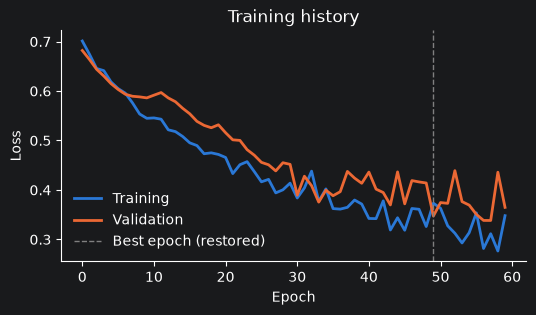

In [10]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(pipeline.history_['train_loss'], color=EARLY, linewidth=2, label='Training')
ax.plot(pipeline.history_['val_loss'], color=LATE, linewidth=2, label='Validation')
ax.axvline(pipeline.fit_report_['best_epoch'], color='grey', linestyle='--', linewidth=1, label='Best epoch (restored)')
ax.set(title='Training history', xlabel='Epoch', ylabel='Loss')
ax.legend(frameon=False)
plt.show()

## 4 Evaluate

All patients get a prediction, even those that don't have any patches.

In [13]:
predictions = pipeline.predict(test)

no_slide = test.present.index[~test.present['slides']]
print(f'{len(no_slide)} of the {len(test)} test patients have no slide. Their predictions:')
display(predictions.loc[no_slide[:]])

6 of the 50 test patients have no slide. Their predictions:


,probability[early],probability[late]
id,,
patient_006,0.599422,0.400578
patient_056,0.694390,0.305610
patient_123,0.040419,0.959581
patient_128,0.881362,0.118638
patient_145,0.839604,0.160396
patient_176,0.024948,0.975052


In [14]:
from kalecancer.evaluate import BalancedAccuracy

metrics = {'auroc': auroc, 'balanced_accuracy': BalancedAccuracy()}

pipeline.evaluate(test, metrics)

auroc                0.922824
balanced_accuracy    0.859606
Name: score, dtype: float64

Evaluating on the training cohort is data leakage. KaleCancer guards against this behaviour.

In [15]:
try:
    pipeline.evaluate(train, metrics)
except ValueError as error:
    print(error)

150 patients were used to fit this pipeline (e.g. ['patient_001', 'patient_002', 'patient_004', 'patient_005', 'patient_007']); evaluate on held-out patients, or pass allow_seen=True


`bootstrap_ci` allows us to calculate confidence intervals instead of a single metric value.

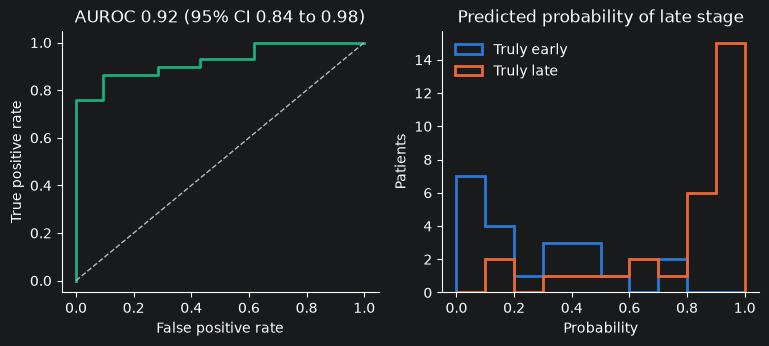

In [16]:
from sklearn.metrics import roc_curve
from kalecancer.evaluate import EvalContext, bootstrap_ci

truth = test.target.frame.loc[predictions.index, 'label']
context = EvalContext(train_target=pipeline.train_target_, classes=['early', 'late'])
interval = bootstrap_ci(auroc, predictions, test.target.frame.loc[predictions.index], context)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.4))

false_positive, true_positive, _ = roc_curve(truth == 'late', predictions['probability[late]'])
left.plot(false_positive, true_positive, color=MODEL, linewidth=2)
left.plot([0, 1], [0, 1], color='#b8b6ae', linestyle='--', linewidth=1)
left.set(title=f'AUROC {interval.estimate:.2f} (95% CI {interval.lower:.2f} to {interval.upper:.2f})',
         xlabel='False positive rate', ylabel='True positive rate')

bins = np.linspace(0, 1, 11)
for stage, colour in [('early', EARLY), ('late', LATE)]:
    right.hist(predictions.loc[truth == stage, 'probability[late]'], bins=bins, histtype='step', linewidth=2, color=colour, label=f'Truly {stage}')
right.set(title='Predicted probability of late stage', xlabel='Probability', ylabel='Patients')
right.yaxis.get_major_locator().set_params(integer=True)
right.legend(frameon=False)
plt.show()

## 5 Does Combining Modalities Help?

Swapping the model takes one line, and everything else stays the same. To compare fairly, we use only patients who have both modalities, and train every candidate for the same number of epochs.

`cross_validate` refits everything in every fold, so this cell takes a couple of minutes.

In [17]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from kalecancer.evaluate import cross_validate
from kalecancer.model import LateFusion, Unimodal

clinical_model = Unimodal('clinical', [clinical_encoder], head)
slide_model = Unimodal('slides', [slide_encoder], head)

candidates = {
    'Clinical only': clinical_model,
    'Slides only': slide_model,
    'Late fusion': LateFusion({'clinical': clinical_model, 'slides': slide_model}, fusion=MaskedMean()),
    'Intermediate fusion': model
}

complete = dataset.subset(dataset.present_ids('slides'))
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
fixed_training = {'validation': None, 'early_stopping': None, 'max_epochs': 40}

results = {
    name: cross_validate(clone(pipeline).set_params(model=candidate, **fixed_training), complete, folds, metrics)
    for name, candidate in candidates.items()
}

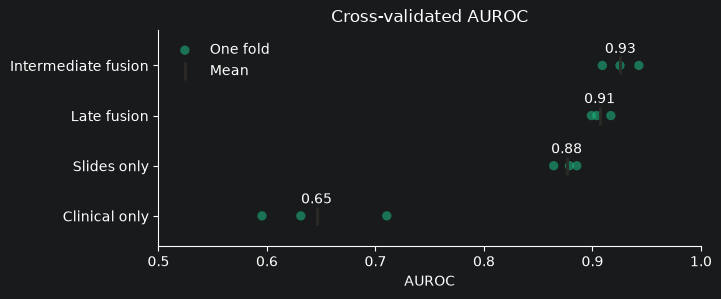

In [19]:
fig, ax = plt.subplots(figsize=(7, 2.8))
for row, (name, result) in enumerate(results.items()):
    scores = result.folds['auroc']
    ax.scatter(scores, [row] * len(scores), s=45, color=MODEL, alpha=0.6, edgecolor='none', label='One fold' if row == 0 else None)
    ax.scatter(scores.mean(), row, s=160, marker='|', color='#2b2a27', linewidth=2, label='Mean' if row == 0 else None)
    ax.annotate(f'{scores.mean():.2f}', (scores.mean(), row), xytext=(0, 9), textcoords='offset points', ha='center')
ax.set_yticks(range(len(results)), results.keys())
ax.set_ylim(-0.6, len(results) - 0.3)
ax.set(title='Cross-validated AUROC', xlabel='AUROC', xlim=(0.5, 1))
ax.legend(frameon=False, loc='upper left')
plt.show()

Given a `baseline`, `bootstrap_ci` scores both models on the same resampled patients, so the interval is of the gain itself.

In [20]:
clinical_pipeline = clone(pipeline).set_params(model=clinical_model, **fixed_training).fit(train)
clinical_predictions = clinical_pipeline.predict(test)

gain = bootstrap_ci(
    auroc, predictions, test.target.frame.loc[predictions.index], context,
    baseline=clinical_predictions.loc[predictions.index]
)
print(f'AUROC gained by adding slides to the clinical table: {gain.estimate:+.2f} (95% CI {gain.lower:+.2f} to {gain.upper:+.2f})')

AUROC gained by adding slides to the clinical table: +0.32 (95% CI +0.17 to +0.48)


## 6 Interpretting the results

The cohort synthesised with these signals: slides carry the most signal, age adds some, and gender adds none.

Can the interpretation tools recover them?

### 6.1 Which modality matters?

These tools mark a modality as absent and measure what the model loses. Each modality is scored on the same patients, so the patients with no slide are left out.

In [21]:
from kalecancer.interpret import leave_one_out_ablation, modality_shapley

shapley = modality_shapley(pipeline, test, auroc)
ablation = leave_one_out_ablation(pipeline, test, auroc)

print(f"Scored on {len(test) - shapley.attrs['n_excluded']} patients")
pd.DataFrame({'Shapley value': shapley, 'AUROC lost when removed': ablation}).round(3)

Scored on 44 patients


,Shapley value,AUROC lost when removed
clinical,0.062,0.062
slides,0.268,0.268


Note: with two modalities, both Shapley and abalation match. With three or more, Shapley also splits the credit fairly between modalities that overlap.

### 6.2 Which clinical features matter?


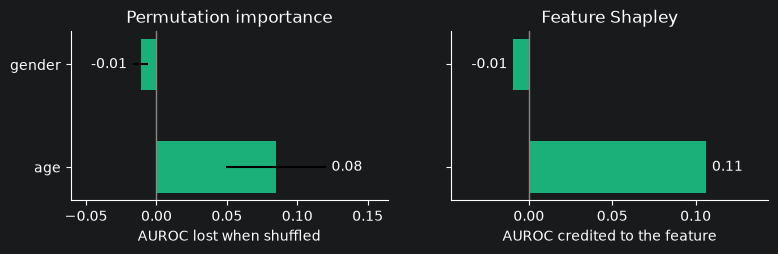

In [22]:
from kalecancer.interpret import feature_shapley, permutation_importance

importance = permutation_importance(pipeline, test, auroc, n_repeats=20, seed=RANDOM_STATE)
feature_values = feature_shapley(pipeline, test, auroc, n_samples=30, seed=RANDOM_STATE)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 2.2), sharey=True)
left.barh(importance.index, importance['mean'], xerr=importance['std'], color=MODEL, height=0.5)
left.set(title='Permutation importance', xlabel='AUROC lost when shuffled')
right.barh(feature_values.index, feature_values, color=MODEL, height=0.5)
right.set(title='Feature Shapley', xlabel='AUROC credited to the feature')
for ax in (left, right):
    ax.bar_label(ax.containers[-1], fmt='%.2f', padding=4)
    ax.axvline(0, color='#8a8880', linewidth=1)
    ax.margins(x=0.32)
plt.show()

### 6.3 Where on the slide?

`attention` shows us how much weight the model gave every patch, and `attention_heatmap` helps us visualise these values.

Our synthetic data records which patches are truly aggressive, so we can compare the two.

In [23]:
import h5py
from kalecancer.interpret import attention, attention_heatmap, save_heatmap

weights = attention(pipeline, test, 'slides')

def read_aggressive(path):
    with h5py.File(path) as f:
        return f['aggressive'][:]

weights['aggressive'] = np.concatenate([read_aggressive(path) for path in weights['file'].unique()])
weights.drop(columns='file').head()

,patient_id,x,y,attention,aggressive
0,patient_000,0,1280,0.014410,False
1,patient_000,0,1536,0.005025,False
2,patient_000,0,1792,0.002580,False
3,patient_000,0,2048,0.003249,False
4,patient_000,0,2304,0.001864,False


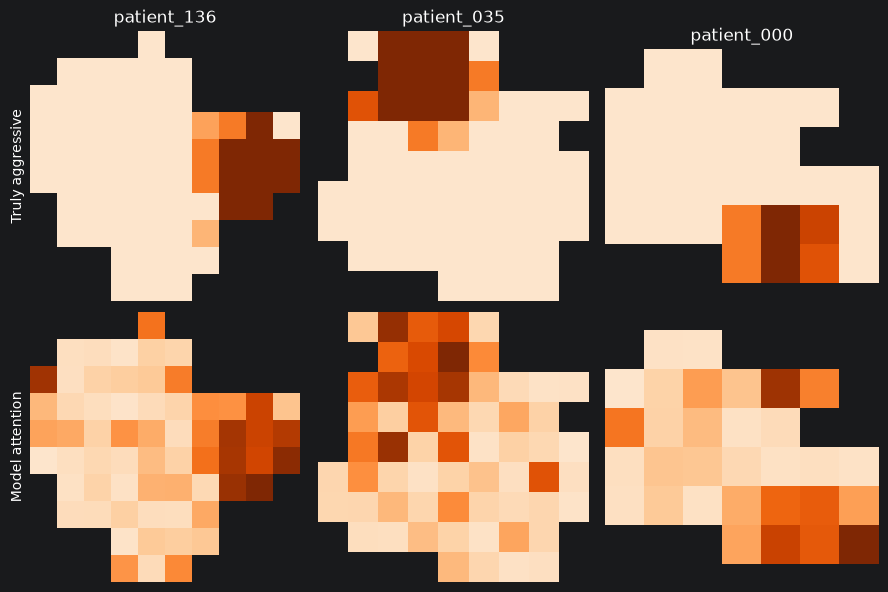

In [24]:
def heatmap(patient, column):
    rows = weights[weights['patient_id'] == patient]
    return attention_heatmap(rows, patch_size=PATCH_SIZE, downsample=2 * PATCH_SIZE, weight_column=column)

patients = predictions.loc[test.present_ids('slides'), 'probability[late]'].nlargest(3).index

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for column, patient in enumerate(patients):
    axes[0, column].imshow(heatmap(patient, 'aggressive'), cmap='Oranges', vmin=-0.15)
    axes[0, column].set_title(patient)
    axes[1, column].imshow(heatmap(patient, 'attention'), cmap='Oranges', vmin=-0.15)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
    ax.spines[:].set_visible(False)
axes[0, 0].set_ylabel('Truly aggressive')
axes[1, 0].set_ylabel('Model attention')
plt.tight_layout()
plt.show()

Those three are the model's most confident late-stage patients, so here is the check across every test slide: for each one, are the patches it attends to most actually aggressive?

In [25]:
def hit_rate(rows):
    return rows.nlargest(rows['aggressive'].sum(), 'attention')['aggressive'].mean()

with_region = weights.groupby('patient_id').filter(lambda rows: rows['aggressive'].any())
hits = with_region.groupby('patient_id')[['attention', 'aggressive']].apply(hit_rate)
chance = with_region.groupby('patient_id')['aggressive'].mean()

print(f'Most-attended patches that are truly aggressive: {hits.mean():.0%} (chance: {chance.mean():.0%}, {len(hits)} slides)')

Most-attended patches that are truly aggressive: 42% (chance: 10%, 44 slides)


Save the results to review them outside Python: a PNG for each heatmap, and a table of weights and coordinates.

In [26]:
save_heatmap(heatmap(patients[0], 'attention'), data_folder + f'/heatmaps/{patients[0]}.png', colormap='Oranges')
weights.to_csv(data_folder + '/heatmaps/attention.csv', index=False)

### 6.4 What has it learned?

`encode` gives you the embedding of any modality, ready for your own analysis.

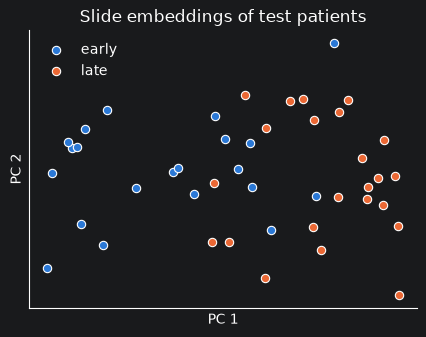

In [27]:
from sklearn.decomposition import PCA

embeddings = pipeline.encode(test, 'slides')
projection = PCA(n_components=2).fit_transform(embeddings)
stages = test.target.frame.loc[embeddings.index, 'label'].to_numpy()

fig, ax = plt.subplots(figsize=(5, 3.6))
for stage, colour in [('early', EARLY), ('late', LATE)]:
    ax.scatter(*projection[stages == stage].T, s=36, color=colour, edgecolor='white', linewidth=0.8, label=stage)
ax.set(title='Slide embeddings of test patients', xlabel='PC 1', ylabel='PC 2', xticks=[], yticks=[])
ax.legend(frameon=False)
plt.show()

## 7 Share It

`dump_config` writes the whole experiment to a YAML file. Anyone can rebuild and retrain it from that file alone, without any of the code above.

In [28]:
import yaml
from pathlib import Path
from kalecancer.pipeline import dump_config, load_pipeline

config_path = Path(data_folder) / 'pipeline.yaml'
config_path.write_text(yaml.safe_dump(dump_config(pipeline), sort_keys=False))

print(*config_path.read_text().splitlines()[:14], '...', sep='\n')

class_path: kalecancer.pipeline.Pipeline
init_args:
  model:
    class_path: kalecancer.model.IntermediateFusion
    init_args:
      encoders:
        clinical:
        - class_path: kalecancer.model.MLP
          init_args:
            in_dim: 2
            hidden_dims:
            - 16
            out_dim: 16
            dropout: 0.25
...


In [29]:
rebuilt = load_pipeline(config_path).fit(train)

print('Same predictions as the original:', np.allclose(rebuilt.predict(test), predictions, atol=1e-4))

Same predictions as the original: True


## KaleCancer Workflow

| You want to | Use |
| --- | --- |
| Join a table and slides by patient | `Tabular`, `PatchFeatures`, `MultimodalDataset` |
| Prepare data | `TableTransform`, `Pipeline` |
| Try different models | `Unimodal`, `IntermediateFusion`, `LateFusion`, `MaskedMean` |
| Get confident estimates | `cross_validate`, `bootstrap_ci`, `Pipeline.evaluate` |
| Explain modalities and features | `modality_shapley`, `leave_one_out_ablation`, `permutation_importance`, `feature_shapley` |
| Interpret slides | `attention`, `attention_heatmap`, `save_heatmap`, `Pipeline.encode` |
| Share the experiment | `dump_config`, `load_pipeline` |

There is more beyond this notebook:

- **Survival outcomes:** `CoxHead`, `kaplan_meier`, `calibration_table` and `patient_report`.
- **Real slides:** `overlay_on_slide` draws a heatmap on the slide image.
- **Larger clinical tables:** `TabICLEncoder` is a pretrained tabular encoder.

To use your own data, point section 1 at your files, then match the encoder sizes in section 2 and the column names in section 3. The rest of the workflow stays the same.